In [ ]:
# BASIC FUNCTIONS

import configparser
from datetime import datetime, timedelta
from getpass import getuser
from os import listdir
from os.path import isdir, join
from pathlib import Path

import pandas as pd

readout_times = pd.read_csv(join("..", "csv", "readout_times.csv"))


def get_readout_time(hdr):
    df = readout_times
    readout_rate = hdr["READRATE"]
    binning = hdr["HBIN"]
    sub_image = hdr["FINALLIN"] - hdr["INITLIN"] + 1
    filter = (
        (df["Readout rate"] == readout_rate)
        & (df["Sub-image"] == sub_image)
        & (df["Binning"] == binning)
    )
    return df[filter]["Readout time"].values[0]


def calc_overhead_between_images(hdr, next_hdr):
    timestamp = datetime.fromisoformat(hdr["DATE-OBS"])
    next_timestamp = datetime.fromisoformat(next_hdr["DATE-OBS"])
    readout_time = get_readout_time(hdr)
    delay = next_timestamp - timestamp
    delay = delay.total_seconds() - hdr["EXPTIME"] - readout_time
    return delay


def read_config_file():
    sparc4_folder = join("C:\\", "Users", getuser(), "SPARC4", "ACS")
    cfg_file = join(sparc4_folder, "acs_config.cfg")
    cfg = configparser.ConfigParser()
    cfg.read(cfg_file)
    return cfg


def get_image_folder():
    cfg = read_config_file()
    today = Path(cfg.get("channel configuration", "image path").strip(r"\""))
    today_list = [file for file in listdir(today) if ".fits" in file]
    if today_list != []:
        return today
    yesterday = datetime.now() - timedelta(days=1)
    yesterday = join(today, "..", yesterday.strftime("%Y%m%d"))
    if not isdir(yesterday):
        raise FileNotFoundError(f"The folder {yesterday} does not exist.")
    return yesterday

In [ ]:
# VERIFY IF THERE IS ANY ZERO IN THE POLARIMETRIC MODE
import os
from os.path import join

import astropy.io.fits as fits
import numpy as np
import pandas as pd

folder = join("C:\\", "Users", "Denis", "Desktop", "tmp", "ch1")
files = os.listdir(folder)
headers = {"INSTMODE": [], "WPPOS": []}

for file in files:
    file_path = join(folder, file)
    hdr = fits.getheader(file_path)
    headers["INSTMODE"].append(hdr["INSTMODE"])
    headers["WPPOS"].append(hdr["WPPOS"])

headers = pd.DataFrame.from_dict(headers)
csv_file = join(folder, "..", "WPPOS.csv")
headers.to_csv(csv_file, index=False)

wrong_header = (headers["INSTMODE"] == "POLAR") & (headers["WPPOS"] == 0)
idxs = np.where(wrong_header)[0]
for idx in idxs:
    print(f"File {files[idx]} has a wrong header!")

In [ ]:
# GET SOME IMAGE HEADER KEYWORDS AND WRITEN THEM INTO A CSV
import os
from os.path import join

import astropy.io.fits as fits
import numpy as np
import pandas as pd

folder = get_image_folder()
files = [file for file in os.listdir(folder) if ".fits" in file]

headers = {
    "FILENAME": [],
    "DATE-OBS": [],
    "NCYCLES": [],
    "CYCLIND": [],
    "NSEQ": [],
    "SEQINDEX": [],
    "WPPOS": [],
    "NFRAMES": [],
    "FRAMEIND": [],
    "EXPTIME": [],
}

for idx, file in enumerate(files):
    file_path = join(folder, file)
    hdr1 = fits.getheader(file_path)

    for key in headers.keys():
        headers[key].append(hdr1[key])

headers = pd.DataFrame.from_dict(headers)
csv_file = join("keywords.csv")
headers.to_csv(csv_file, index=False)

In [ ]:
# GET SOME IMAGE HEADER KEYWORDS AND WRITEN THEM INTO A CSV WITH DEADTIME
import os
from os.path import join

import astropy.io.fits as fits
import numpy as np
import pandas as pd

folder = get_image_folder()
files = [file for file in os.listdir(folder) if ".fits" in file]

headers = {
    "FILENAME": [],
    "DATE-OBS": [],
    "NCYCLES": [],
    "CYCLIND": [],
    "NSEQ": [],
    "SEQINDEX": [],
    "NFRAMES": [],
    "FRAMEIND": [],
    "EXPTIME": [],
    "OVERHEAD": [],
}

for idx, file in enumerate(files[:-1]):
    file_path = join(folder, file)
    hdr1 = fits.getheader(file_path)
    file_path = join(folder, files[idx + 1])
    hdr2 = fits.getheader(file_path)

    for key in headers.keys():
        if key == "OVERHEAD":
            continue
        headers[key].append(hdr1[key])
    headers["OVERHEAD"].append(calc_overhead_between_images(hdr1, hdr2))

headers = pd.DataFrame.from_dict(headers)
csv_file = join("keywords.csv")
headers.to_csv(csv_file, index=False)

In [ ]:
# CALCULATE INTERVAL BETWEEN IMAGES

from pathlib import Path
import astropy.io.fits as fits
from os import listdir
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

today = Path("C:/") / "images" / "today"
images = listdir(today)
delays = []
for idx, image in enumerate(images[:-1]):
    hdr = fits.getheader(today / image)
    time_stamp1 = datetime.fromisoformat(hdr["DATE-OBS"])
    exptime = timedelta(seconds=hdr["EXPTIME"])
    hdr = fits.getheader(today / images[idx + 1])
    time_stamp2 = datetime.fromisoformat(hdr["DATE-OBS"])
    delay = time_stamp2 - time_stamp1 - exptime
    delays.append(delay.total_seconds() * 1e3)

plt.plot(delays, "bo-")
plt.ylabel("time (s)")
# plt.xlim(100,500)
plt.ylim(4, 5)
plt.show()


In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

image = Image.open(
    r"C:\Users\Denis\Downloads\20260701_tests\20260701_tests\SDK 2.104.30167.0.tiff"
)
image.show()
# image = np.array(image)
# image

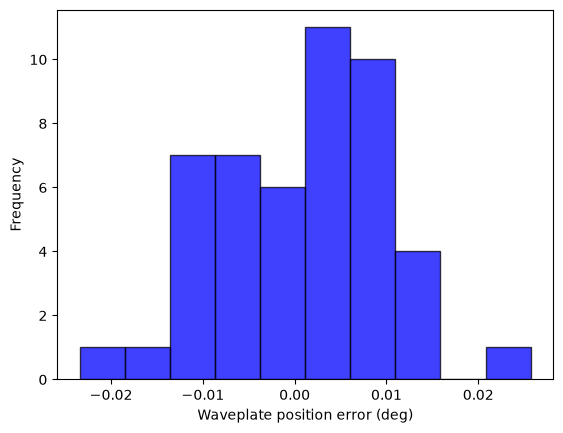

In [ ]:
from astropy.io import fits
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

wpang_list: list[float] = []
wppos_list: list[int] = []
error_list: list[float] = []
images_folder = Path(Path.cwd().anchor) / "images" / "today"
images = list(images_folder.glob("*.fits"))
headers = [fits.getheader(image) for image in images]
rgn = np.random.default_rng(seed=42)

for header in headers:
    if header["INSTMODE"] == "PHOT":
        continue
    wppos_list.append(header["WPPOS"])
    wpang_list.append(header["WPANG"])

for idx, (wppos, wpang) in enumerate(zip(wppos_list, wpang_list)):
    expected_ang = 22.5 * (wppos - 1)
    error = expected_ang - wpang
    error_list.append(error)


plt.hist(error_list, color="blue", edgecolor="black", alpha=0.75)
plt.xlabel("Waveplate position error (deg)")
plt.ylabel("Frequency")
image_path = Path.cwd() / "_files" / "wppos_error_hist.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()
